# Mini Task 09 | VOiCES: Background Sounds and Speech Activity

**Amirkabir University of Technology — School of Computer Engineering**  
**M.Sc. Artificial Intelligence and Robotics**  
**Course:** Digital Speech Processing  
**Instructor:** Dr. Khaloei  
**Student:** Baraa Atmeesh  
**Student ID:** 403131113

I study two related questions: whether I can identify environmental sounds from short-term acoustic features, and how different voice activity detectors behave on distant-microphone speech. I use the 90-degree VOiCES subset. My analysis uses a speaker-disjoint split, a spectral feature representation, and a separate VAD experiment with automatically derived reference labels.

I report measured classification metrics only after executing the cells. The VAD reference is not manually annotated speech, so I distinguish agreement with the reference from verified ground-truth performance.

## 1. Setup

I use a consistent random seed and keep all outputs inside this project folder in the Colab runtime. The files can be downloaded at the end. The subset repository contains archived recordings, so the first run needs an internet connection and enough disk space for the download and extracted WAV files.

In [1]:
import sys, subprocess, importlib.util
packages = {'numpy':'numpy','pandas':'pandas','scipy':'scipy','soundfile':'soundfile',
            'sklearn':'scikit-learn','matplotlib':'matplotlib','torch':'torch',
            'silero_vad':'silero-vad'}
missing = [pip_name for module, pip_name in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

from pathlib import Path
from collections import Counter
from scipy.signal import stft
from scipy.ndimage import median_filter
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from silero_vad import load_silero_vad, get_speech_timestamps

RNG = 29
np.random.seed(RNG)
torch.manual_seed(RNG)
torch.set_num_threads(1)
BASE = Path('/content/Baraa_MT9') if Path('/content').exists() else Path.cwd() / 'Baraa_MT9'
AUDIO = BASE / 'audio'
FIG = BASE / 'figures'
OUT = BASE / 'results'
for folder in (BASE, AUDIO, FIG, OUT):
    folder.mkdir(parents=True, exist_ok=True)
BACKGROUND = ['none', 'babb', 'musi', 'tele']
DISPLAY = {'none':'No distractor', 'babb':'Babble', 'musi':'Music', 'tele':'Television'}
print('Working folder:', BASE)

Working folder: /content/Baraa_MT9


## 2. Reading the recordings

The filename stores the room, distractor, speaker and microphone placement. I parse these fields instead of assigning classes from the sound. Archive members contain paths from another machine; I only use each member's final filename and never extract their original directory paths.

In [2]:
import tarfile
REPO = Path('/content/VOiCES-subset') if Path('/content').exists() else Path.cwd() / 'VOiCES-subset'
if not REPO.exists():
    subprocess.check_call(['git', 'clone', '--depth', '1',
                           'https://github.com/Lab41/VOiCES-subset.git', str(REPO)])
archives = sorted(REPO.glob('VOiCES_90_*.tar'))
if not archives:
    raise FileNotFoundError('The VOiCES_90_*.tar archives were not found.')

def parse_name(file_name):
    parts = Path(file_name).stem.split('-')
    if len(parts) != 12 or parts[:3] != ['Lab41', 'SRI', 'VOiCES']:
        return None
    if parts[4] not in BACKGROUND or not parts[5].startswith('sp'):
        return None
    return {'filename': Path(file_name).name, 'label':parts[4],
            'speaker':parts[5], 'room':parts[3], 'mic':parts[8],
            'position':parts[10], 'utterance': '-'.join([*parts[:8],parts[11]])}

rows, skipped = [], []
seen = set()
for archive_path in archives:
    with tarfile.open(archive_path, 'r:*') as tar:
        for member in tar:
            if not member.isfile() or not member.name.lower().endswith('.wav'):
                continue
            info = parse_name(member.name)
            if info is None or info['filename'].startswith('._'):
                skipped.append(Path(member.name).name)
                continue
            if info['filename'] in seen:
                raise ValueError('Duplicate filename across archives: ' + info['filename'])
            seen.add(info['filename'])
            target = AUDIO / info['filename']
            if not target.exists():
                stream = tar.extractfile(member)
                if stream is None:
                    skipped.append(info['filename'])
                    continue
                with target.open('wb') as handle:
                    while True:
                        chunk = stream.read(1024 * 1024)
                        if not chunk: break
                        handle.write(chunk)
            try:
                audio_info = sf.info(str(target))
                if audio_info.frames < 400 or audio_info.samplerate != 16000:
                    raise ValueError('Wrong duration or sampling rate')
                rows.append({**info, 'path':str(target),
                             'duration_s':audio_info.duration,
                             'sample_rate':audio_info.samplerate})
            except Exception:
                skipped.append(info['filename'])
                target.unlink(missing_ok=True)

df = pd.DataFrame(rows).sort_values('filename').reset_index(drop=True)
if df.empty or df['filename'].duplicated().any():
    raise RuntimeError('No valid and unique VOiCES recordings could be loaded.')
print('Usable files:',len(df), '| Skipped:',len(skipped))
print('Speakers:',df.speaker.nunique(), '| Utterances:',df.utterance.nunique())
print(df['label'].map(DISPLAY).value_counts().to_string())
print('Total hours:', round(df.duration_s.sum()/3600, 2))
df.drop(columns='path').to_csv(OUT/'recording_inventory.csv', index=False)

Usable files: 908 | Skipped: 1
Speakers: 104 | Utterances: 721
label
Music            231
Babble           228
No distractor    227
Television       222
Total hours: 3.92


## 3. Exploring the background conditions

I first check how the distractors are distributed across microphone positions. I also compare time-frequency examples. This lets me inspect whether speech masks the background and motivates my low-energy feature experiment. I treat the plots as examples, not as proof that all recordings behave identically.

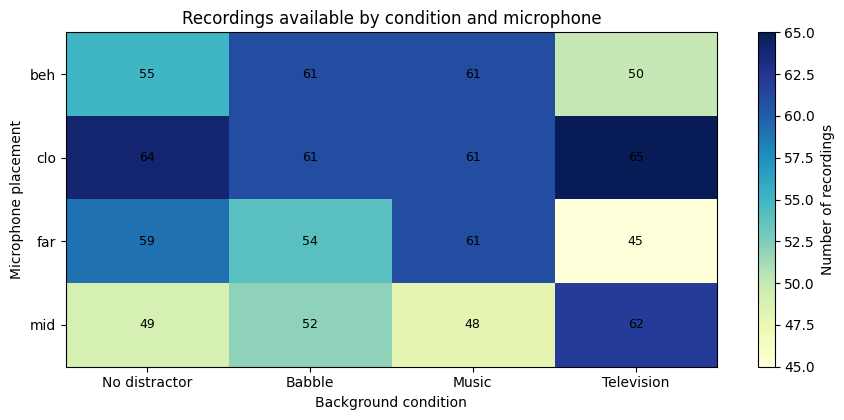

In [3]:
ct = pd.crosstab(df['position'], df['label']).reindex(columns=BACKGROUND, fill_value=0)
fig, ax = plt.subplots(figsize=(9,4.3))
im = ax.imshow(ct.to_numpy(), aspect='auto', cmap='YlGnBu')
ax.set_xticks(range(4), [DISPLAY[c] for c in BACKGROUND])
ax.set_yticks(range(len(ct)), ct.index)
for (i,j), value in np.ndenumerate(ct.to_numpy()):
    ax.text(j,i,str(value),ha='center',va='center',fontsize=9)
ax.set_xlabel('Background condition'); ax.set_ylabel('Microphone placement')
ax.set_title('Recordings available by condition and microphone')
fig.colorbar(im, ax=ax, label='Number of recordings')
fig.tight_layout(); fig.savefig(FIG/'01_condition_microphone_matrix.png', dpi=170)
plt.show()

## 4. Frame-level spectral representation

I use 25 ms Hann-windowed frames separated by 10 ms. Each frame is represented by 16 log-Mel energies and four complementary measurements: log RMS, zero-crossing rate, spectral centroid, and spectral flatness. Unlike a conventional MFCC-mean baseline, I summarize each feature by its **median and interquartile range**. This gives 40 summary values for each recording.

I compare the full signal with the lowest-energy 30% of frames. These frames are a useful approximation to quiet intervals, but they are not guaranteed to be speech-free.

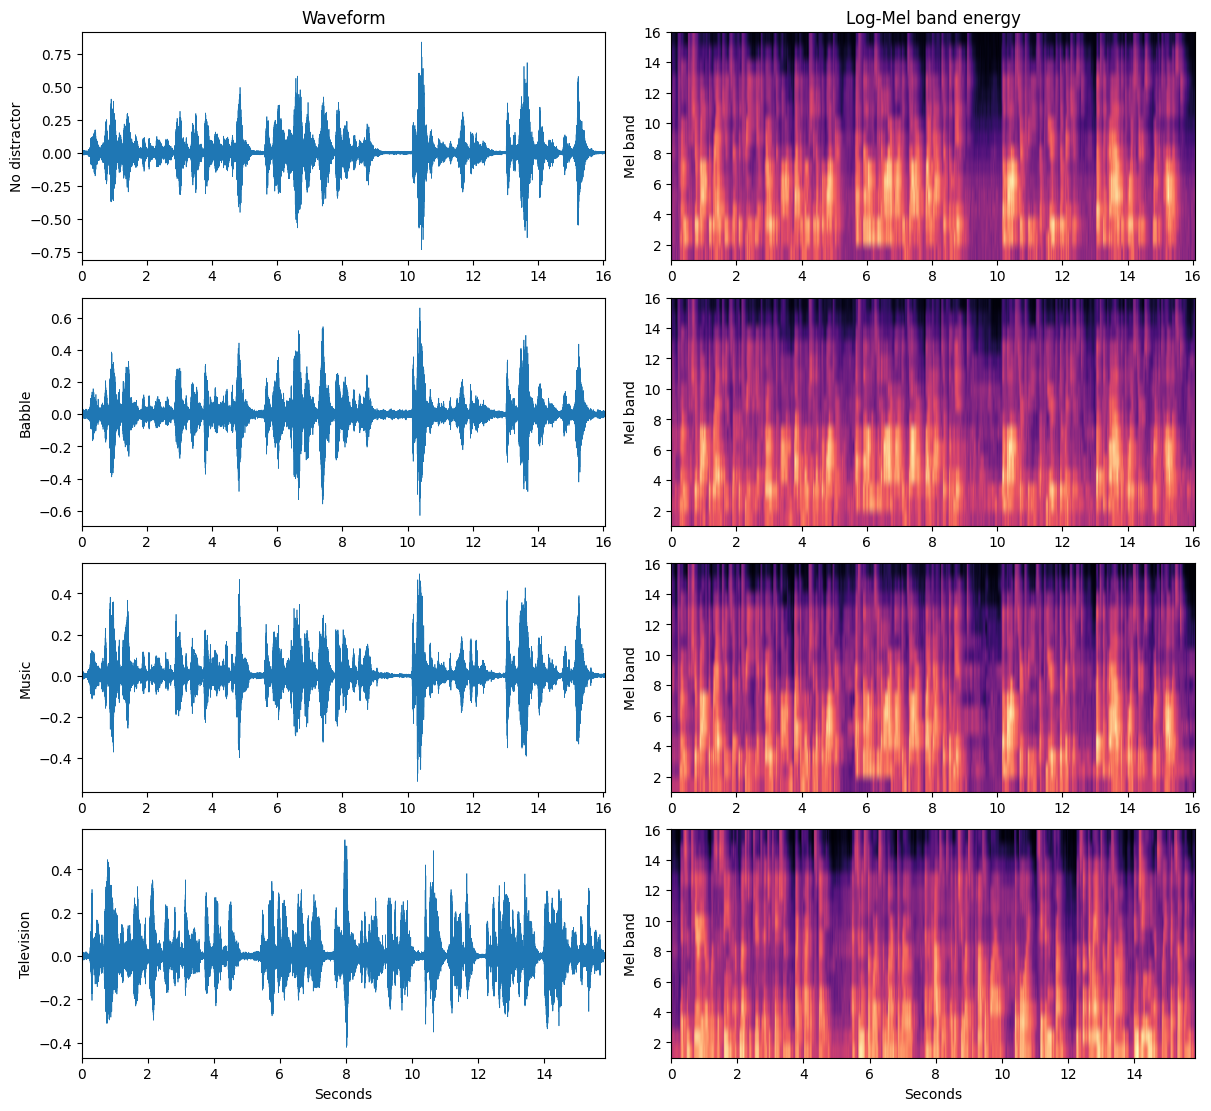

In [4]:
SR, FRAME, HOP, FFT, N_MELS = 16000, 400, 160, 512, 16

def hz_to_mel(hz):
    return 2595.0 * np.log10(1.0 + np.asarray(hz)/700.0)

def mel_to_hz(mel):
    return 700.0 * (10 ** (np.asarray(mel)/2595.0) - 1.0)

def make_melbank():
    centers = mel_to_hz(np.linspace(hz_to_mel(80),hz_to_mel(7800),N_MELS+2))
    hz_grid = np.fft.rfftfreq(FFT,1/SR)
    bank = np.zeros((N_MELS,len(hz_grid)),dtype=np.float32)
    for i in range(N_MELS):
        left,middle,right = centers[i:i+3]
        bank[i] = np.maximum(0,np.minimum((hz_grid-left)/(middle-left),
                                            (right-hz_grid)/(right-middle)))
    bank /= np.maximum(bank.sum(axis=1,keepdims=True),1e-9)
    return bank
MELBANK = make_melbank()
TRACK_NAMES = [f'logmel_{k+1:02d}' for k in range(N_MELS)] + ['log_rms','zcr','centroid','flatness']
COLS = [f'{kind}_{name}' for kind in ('median','iqr') for name in TRACK_NAMES]

def read_wave(path):
    y, sr = sf.read(path,dtype='float32',always_2d=False)
    if y.ndim == 2: y = np.mean(y,axis=1)
    if sr != SR: raise ValueError(f'Expected {SR} Hz, received {sr}')
    if len(y) < FRAME: raise ValueError('Signal shorter than one analysis frame')
    return np.asarray(y,dtype=np.float32)

def spectral_tracks(y):
    y = np.asarray(y,dtype=np.float32)
    _, times, z = stft(y,fs=SR,window='hann',nperseg=FRAME,
                        noverlap=FRAME-HOP,nfft=FFT,boundary=None,padded=False)
    power = np.maximum(np.abs(z)**2,1e-12)
    mel = np.log10(MELBANK @ power + 1e-10).T
    frames = np.lib.stride_tricks.sliding_window_view(y,FRAME)[::HOP]
    n = min(len(frames),len(times),len(mel))
    frames,mel,power,times = frames[:n],mel[:n],power[:,:n],times[:n]
    rms = np.sqrt(np.mean(frames.astype(np.float64)**2,axis=1))
    zcr = np.mean(frames[:,1:]*frames[:,:-1] < 0,axis=1)
    f = np.fft.rfftfreq(FFT,1/SR)
    centroid = (power*f[:,None]).sum(axis=0)/(power.sum(axis=0)+1e-10)/8000
    geometric = np.exp(np.mean(np.log(power),axis=0))
    flatness = geometric/np.maximum(np.mean(power,axis=0),1e-12)
    tracks = np.column_stack([mel,np.log10(rms+1e-9),zcr,centroid,flatness])
    assert tracks.shape[1] == len(TRACK_NAMES) and np.isfinite(tracks).all()
    return times, tracks

def summarise(tracks,quiet_only=False):
    block = tracks
    if quiet_only:
        k = max(3,int(np.ceil(.30*len(tracks))))
        quiet = np.argsort(tracks[:,N_MELS])[:k]
        block = tracks[quiet]
    q25, med, q75 = np.percentile(block,[25,50,75],axis=0)
    result = np.r_[med, q75-q25]
    assert result.shape == (40,) and np.isfinite(result).all()
    return result

sample_rows = [df.loc[df.label.eq(b)].iloc[0] for b in BACKGROUND]
fig, axes = plt.subplots(4,2,figsize=(12,11),layout='constrained')
for i,rec in enumerate(sample_rows):
    y = read_wave(rec.path)
    times, tracks = spectral_tracks(y)
    x = np.arange(len(y))/SR
    axes[i,0].plot(x,y,lw=.5)
    axes[i,0].set_ylabel(DISPLAY[rec.label])
    axes[i,0].set_xlim(0,x[-1])
    axes[i,1].imshow(tracks[:,:N_MELS].T,origin='lower',aspect='auto',
                     extent=[times[0],times[-1],1,N_MELS],cmap='magma')
    axes[i,1].set_xlim(0,x[-1])
    axes[i,1].set_ylabel('Mel band')
axes[0,0].set_title('Waveform'); axes[0,1].set_title('Log-Mel band energy')
axes[-1,0].set_xlabel('Seconds'); axes[-1,1].set_xlabel('Seconds')
fig.savefig(FIG/'02_audio_gallery.png',dpi=160)
plt.show()

## 5. Creating the recording-level feature table

I calculate both representations in the same analysis pass and cache them. I then check that each feature vector is finite and that every recording has only one row. If an audio file fails to decode, I keep its filename in a separate log rather than silently replacing its features.

In [5]:
cache = OUT/'spectral_features_40.csv'
if cache.exists():
    features = pd.read_csv(cache)
    if set(features.filename)!=set(df.filename):
        raise ValueError('Cached features do not match current audio inventory. Delete the cache and rerun.')
else:
    extracted, failures = [], []
    for index,rec in enumerate(df.itertuples(index=False),start=1):
        try:
            _, tracks = spectral_tracks(read_wave(rec.path))
            whole = summarise(tracks,False)
            quiet = summarise(tracks,True)
            extracted.append({'filename':rec.filename,'label':rec.label,'speaker':rec.speaker,
                              **{f'w_{name}':v for name,v in zip(COLS,whole)},
                              **{f'q_{name}':v for name,v in zip(COLS,quiet)}})
        except Exception as exc:
            failures.append((rec.filename,str(exc)))
        if index%100==0: print(f'{index}/{len(df)} recordings processed')
    if failures:
        pd.DataFrame(failures,columns=['filename','reason']).to_csv(OUT/'feature_failures.csv',index=False)
        raise RuntimeError(f'Feature extraction failed for {len(failures)} files. See feature_failures.csv')
    features = pd.DataFrame(extracted)
    features.to_csv(cache,index=False)
assert features.filename.is_unique and set(features.filename)==set(df.filename)
W_COLS = ['w_'+c for c in COLS]
Q_COLS = ['q_'+c for c in COLS]
print('Feature rows:',len(features),'| Representation size:',len(W_COLS))
print('All finite:',np.isfinite(features[W_COLS+Q_COLS].to_numpy()).all())

100/908 recordings processed
200/908 recordings processed
300/908 recordings processed
400/908 recordings processed
500/908 recordings processed
600/908 recordings processed
700/908 recordings processed
800/908 recordings processed
900/908 recordings processed
Feature rows: 908 | Representation size: 40
All finite: True


## 6. Background classification: speaker-independent evaluation

I divide the data by speaker, with 25% of speakers reserved for testing. I compare five models under the same split. My model selection uses four folds of *training speakers only*. I select the combination with the highest cross-validated macro-F1, then report its untouched test-set confusion matrix. This avoids choosing the final model after looking at test accuracy.

In [6]:
from sklearn.base import clone
split = GroupShuffleSplit(n_splits=1,test_size=.25,random_state=RNG)
tr,te = next(split.split(features,features.label,features.speaker))
train = features.iloc[tr]; test = features.iloc[te]
assert set(train.speaker).isdisjoint(set(test.speaker))
assert set(train.label)==set(BACKGROUND) and set(test.label)==set(BACKGROUND)

MODELS = {
    'Linear SVM':make_pipeline(StandardScaler(),LinearSVC(C=.5,max_iter=8000,random_state=RNG)),
    'MLP (48,24)':make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(48,24),
                                             max_iter=500,random_state=RNG)),
    'Extra Trees':ExtraTreesClassifier(n_estimators=180,min_samples_leaf=2,
                                       random_state=RNG,n_jobs=-1),
    'Hist. Gradient Boosting':HistGradientBoostingClassifier(max_iter=90,max_leaf_nodes=15,
                                                              random_state=RNG),
    'KNN (7)':make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=7)),
}
rows=[]
cv=GroupKFold(n_splits=4)
for view, columns in [('Whole recording',W_COLS),('Low-energy 30%',Q_COLS)]:
    xtr=train[columns].to_numpy()
    for name, model in MODELS.items():
        scores=cross_validate(model,xtr,train.label,groups=train.speaker,cv=cv,
                              scoring={'f1':'f1_macro','accuracy':'accuracy'},n_jobs=1)
        rows.append({'feature_set':view,'model':name,
                     'cv_macro_f1':np.mean(scores['test_f1']),
                     'cv_std_f1':np.std(scores['test_f1']),
                     'cv_accuracy':np.mean(scores['test_accuracy'])})
selection=pd.DataFrame(rows).sort_values(['cv_macro_f1','cv_accuracy'],ascending=False)
selection.to_csv(OUT/'background_training_cv.csv',index=False)
print(selection.to_string(index=False,float_format=lambda x:f'{x:.3f}'))

best=selection.iloc[0]
selected_cols = W_COLS if best.feature_set=='Whole recording' else Q_COLS
chosen = clone(MODELS[best.model]).fit(train[selected_cols].to_numpy(),train.label)
yhat = chosen.predict(test[selected_cols].to_numpy())
print('\nSelected on training CV:',best.model,'/',best.feature_set)
print('Held-out accuracy:',round(accuracy_score(test.label,yhat),4))
print('Held-out macro F1:',round(f1_score(test.label,yhat,average='macro'),4))
print(classification_report(test.label,yhat,labels=BACKGROUND,zero_division=0))
summary = pd.DataFrame([{'chosen_model':best.model,'chosen_features':best.feature_set,
                         'cv_macro_f1':best.cv_macro_f1,'test_accuracy':accuracy_score(test.label,yhat),
                         'test_macro_f1':f1_score(test.label,yhat,average='macro'),
                         'n_train':len(train),'n_test':len(test),
                         'n_train_speakers':train.speaker.nunique(),
                         'n_test_speakers':test.speaker.nunique()}])
summary.to_csv(OUT/'background_holdout_metrics.csv',index=False)
preds = test[['filename','label','speaker']].copy()
preds['predicted_label']=yhat
preds.to_csv(OUT/'background_test_predictions.csv',index=False)

    feature_set                   model  cv_macro_f1  cv_std_f1  cv_accuracy
 Low-energy 30%             MLP (48,24)        0.843      0.042        0.845
 Low-energy 30%              Linear SVM        0.826      0.031        0.829
 Low-energy 30% Hist. Gradient Boosting        0.808      0.026        0.810
 Low-energy 30%             Extra Trees        0.787      0.058        0.792
 Low-energy 30%                 KNN (7)        0.684      0.052        0.694
Whole recording              Linear SVM        0.651      0.023        0.655
Whole recording             MLP (48,24)        0.637      0.070        0.637
Whole recording Hist. Gradient Boosting        0.634      0.025        0.636
Whole recording             Extra Trees        0.568      0.036        0.582
Whole recording                 KNN (7)        0.491      0.017        0.499

Selected on training CV: MLP (48,24) / Low-energy 30%
Held-out accuracy: 0.8118
Held-out macro F1: 0.7993
              precision    recall  f1-score   

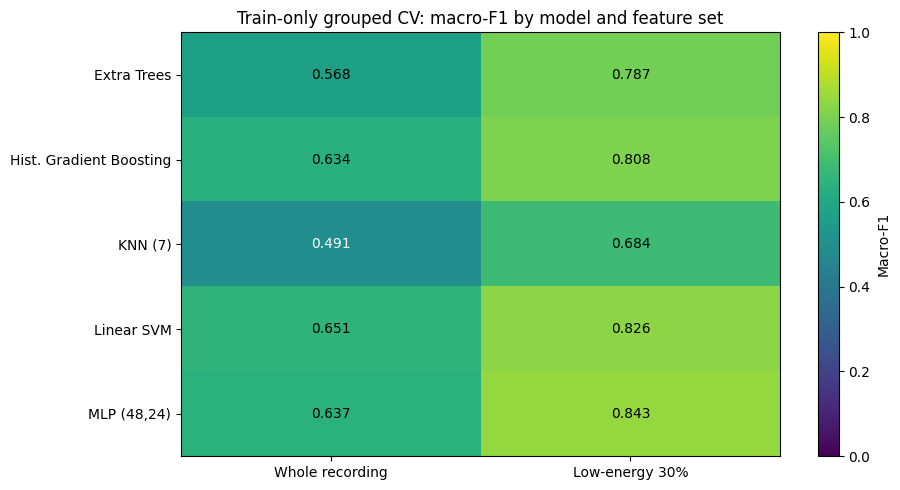

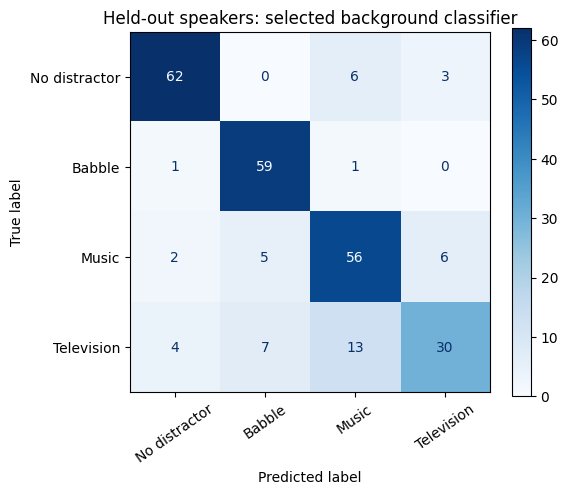

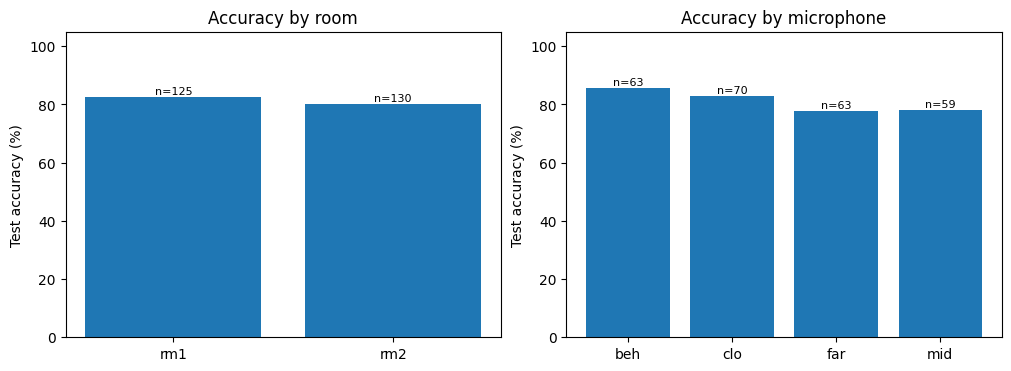

In [7]:
fig,ax=plt.subplots(figsize=(9.5,5))
pivot=selection.pivot(index='model',columns='feature_set',values='cv_macro_f1')
pivot=pivot[['Whole recording','Low-energy 30%']]
image=ax.imshow(pivot,cmap='viridis',vmin=0,vmax=1,aspect='auto')
ax.set_xticks([0,1],pivot.columns)
ax.set_yticks(range(len(pivot)),pivot.index)
for (i,j),value in np.ndenumerate(pivot.to_numpy()):
    ax.text(j,i,f'{value:.3f}',ha='center',va='center',color='white' if value<.55 else 'black')
ax.set_title('Train-only grouped CV: macro-F1 by model and feature set')
fig.colorbar(image,ax=ax,label='Macro-F1')
fig.tight_layout();fig.savefig(FIG/'03_cv_model_heatmap.png',dpi=170);plt.show()

fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(test.label,yhat,labels=BACKGROUND,
                                      display_labels=[DISPLAY[k] for k in BACKGROUND],
                                      cmap='Blues',ax=ax,xticks_rotation=35)
ax.set_title('Held-out speakers: selected background classifier')
fig.tight_layout();fig.savefig(FIG/'04_background_confusion.png',dpi=170);plt.show()

compare = preds.merge(df[['filename','room','position']],on='filename',validate='one_to_one')
compare['correct']=(compare.label==compare.predicted_label).astype(float)
fig,axes=plt.subplots(1,2,figsize=(10,3.6),layout='constrained')
for ax,group,label in [(axes[0],'room','Room'),(axes[1],'position','Microphone')]:
    rates=compare.groupby(group).correct.agg(['mean','count']).sort_index()
    ax.bar(rates.index,100*rates['mean'])
    ax.set_ylim(0,105);ax.set_title(f'Accuracy by {label.lower()}')
    ax.set_ylabel('Test accuracy (%)')
    for j,(_,r) in enumerate(rates.iterrows()):
        ax.text(j,100*r['mean']+1,f'n={int(r["count"])}',ha='center',fontsize=8)
fig.savefig(FIG/'05_test_across_conditions.png',dpi=170);plt.show()

## 7. VAD: approximate speech reference from matching microphones

I found 108 recordings with matching close and behind microphones. I generate labels from the close microphone using Silero, then compare detectors on the distant microphone. I save each processed pair separately, so I can continue the VAD experiment if the runtime stops. A new Colab runtime does not preserve `/content` automatically; for long-term storage I can copy the project to Google Drive.

The reference is automatic, not manually annotated ground truth.


In [8]:
from silero_vad import load_silero_vad, get_speech_timestamps

vad_model = load_silero_vad()
paired = []
for utterance, group in df.groupby('utterance'):
    close = group.loc[group.mic.eq('mc01')]
    distant = group.loc[group.mic.eq('mc07')]
    if len(close) == 1 and len(distant) == 1:
        a, b = close.iloc[0], distant.iloc[0]
        paired.append({'utterance': utterance, 'speaker': a.speaker,
                       'label': a.label, 'close_path': a.path,
                       'far_path': b.path, 'far_filename': b.filename})
pairs = pd.DataFrame(paired)
if pairs.empty:
    raise RuntimeError('No close/behind microphone pairs were found.')
print('Identical-condition microphone pairs:', len(pairs))
print(pairs.label.value_counts().to_string())

def intervals_as_frames(wave, times):
    intervals = get_speech_timestamps(torch.from_numpy(wave.copy()), vad_model,
                                      sampling_rate=SR, return_seconds=True)
    result = np.zeros(len(times), dtype=bool)
    for span in intervals:
        result |= (times >= span['start']) & (times < span['end'])
    return result

pair_cache = OUT / 'vad_pair_cache'
pair_cache.mkdir(parents=True, exist_ok=True)
pair_rows = []
reused = 0
for i, p in enumerate(pairs.itertuples(index=False), start=1):
    checkpoint = pair_cache / (Path(p.far_filename).stem + '.npz')
    recovered = False
    if checkpoint.is_file():
        try:
            with np.load(checkpoint, allow_pickle=False) as saved:
                times = saved['times']
                distant_tracks = saved['tracks']
                reference = saved['reference'].astype(bool)
                silero_far = saved['silero'].astype(bool)
            recovered = (len(times) == len(reference) == len(silero_far) == len(distant_tracks)
                         and len(times) > 0 and distant_tracks.shape[1] == len(TRACK_NAMES)
                         and np.isfinite(distant_tracks).all())
        except (OSError, ValueError, KeyError, EOFError):
            recovered = False
    if recovered:
        reused += 1
    else:
        near = read_wave(p.close_path)
        distant = read_wave(p.far_path)
        size = min(len(near), len(distant))
        near, distant = near[:size], distant[:size]
        times, distant_tracks = spectral_tracks(distant)
        reference = intervals_as_frames(near, times)
        silero_far = intervals_as_frames(distant, times)
        tmp = checkpoint.with_suffix('.writing.npz')
        np.savez_compressed(tmp, times=times.astype('float32'),
                            tracks=distant_tracks.astype('float32'),
                            reference=reference.astype('uint8'),
                            silero=silero_far.astype('uint8'))
        tmp.replace(checkpoint)
    pair_rows.append({'speaker': p.speaker, 'background': p.label,
                      'filename': p.far_filename, 'times': times,
                      'tracks': distant_tracks, 'reference': reference,
                      'silero': silero_far})
    if i % 10 == 0 or i == len(pairs):
        print(f'VAD pairs completed: {i}/{len(pairs)}; reused from cache: {reused}')
print('Frame-level VAD records prepared:', len(pair_rows))


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Identical-condition microphone pairs: 108
label
none    28
musi    27
tele    27
babb    26
VAD pairs completed: 10/108; reused from cache: 0
VAD pairs completed: 20/108; reused from cache: 0
VAD pairs completed: 30/108; reused from cache: 0
VAD pairs completed: 40/108; reused from cache: 0
VAD pairs completed: 50/108; reused from cache: 0
VAD pairs completed: 60/108; reused from cache: 0
VAD pairs completed: 70/108; reused from cache: 0
VAD pairs completed: 80/108; reused from cache: 0
VAD pairs completed: 90/108; reused from cache: 0
VAD pairs completed: 100/108; reused from cache: 0
VAD pairs completed: 108/108; reused from cache: 0
Frame-level VAD records prepared: 108


## 8. VAD comparison on speakers not used for training

I compare four decisions: an all-speech baseline, a simple adaptive-energy detector, a frame-level logistic regression model trained from the reference labels, and Silero applied to the distant microphone. The energy threshold is selected only on training pairs. For the learned detector I limit the training frames per recording and use class balancing. I keep all frames of the test speakers untouched for evaluation.

In [9]:
from sklearn.metrics import precision_score, recall_score
speaker_names=np.array(sorted({p['speaker'] for p in pair_rows}))
if len(speaker_names)<4: raise RuntimeError('Too few speakers for an independent VAD split.')
vad_split=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=RNG)
left,right=next(vad_split.split(pair_rows, groups=[r['speaker'] for r in pair_rows]))
training=[pair_rows[i] for i in left]
testing=[pair_rows[i] for i in right]
assert {r['speaker'] for r in training}.isdisjoint({r['speaker'] for r in testing})

def energy_decision(tracks,relative):
    log_rms=tracks[:,N_MELS]
    lo,hi=np.percentile(log_rms,[10,95])
    threshold=lo+relative*(hi-lo)
    return median_filter((log_rms>threshold).astype(np.uint8),size=11).astype(bool)

thresholds=np.linspace(.05,.65,13)
score_grid=[]
for threshold in thresholds:
    y_true=np.concatenate([r['reference'] for r in training])
    y_pred=np.concatenate([energy_decision(r['tracks'],threshold) for r in training])
    score_grid.append(f1_score(y_true,y_pred,zero_division=0))
energy_parameter=float(thresholds[int(np.argmax(score_grid))])
print('Energy threshold selected on training data:',energy_parameter)

rng=np.random.default_rng(RNG)
train_x, train_y=[],[]
for r in training:
    yy=r['reference']
    idx=np.arange(len(yy))
    if len(idx)>300: idx=np.sort(rng.choice(idx,300,replace=False))
    train_x.append(r['tracks'][idx]);train_y.append(yy[idx].astype(int))
train_x=np.vstack(train_x);train_y=np.concatenate(train_y)
frame_model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=800,
                                          class_weight='balanced',random_state=RNG))
frame_model.fit(train_x,train_y)

comparisons=[]
for rec in testing:
    true=rec['reference']
    predictions={
        'Always speech':np.ones_like(true,dtype=bool),
        'Adaptive energy':energy_decision(rec['tracks'],energy_parameter),
        'Frame logistic regression':median_filter(frame_model.predict(rec['tracks']).astype(np.uint8),
                                                    size=11).astype(bool),
        'Silero (distant)':rec['silero'],
    }
    for method,pred in predictions.items():
        comparisons.append({'speaker':rec['speaker'],'background':rec['background'],
                            'filename':rec['filename'],'method':method,
                            'n_frames':len(true),'tp':int(np.sum(true & pred)),
                            'tn':int(np.sum(~true & ~pred)),
                            'fp':int(np.sum(~true & pred)),
                            'fn':int(np.sum(true & ~pred))})
vad_detail=pd.DataFrame(comparisons)
vad_detail.to_csv(OUT/'vad_pair_confusion_counts.csv',index=False)

def summarise_counts(group):
    tp,tn,fp,fn=group[['tp','tn','fp','fn']].sum()
    n=tp+tn+fp+fn
    return pd.Series({'frames':n,'accuracy':(tp+tn)/n,
                      'precision':tp/max(1,tp+fp),'recall':tp/max(1,tp+fn),
                      'f1':2*tp/max(1,2*tp+fp+fn),
                      'false_alarm':fp/max(1,fp+tn),
                      'miss':fn/max(1,fn+tp)})
vad_overall=pd.DataFrame([{'method':name, **summarise_counts(block).to_dict()}
             for name,block in vad_detail.groupby('method',sort=False)])
vad_by_noise=pd.DataFrame([{'background':key[0], 'method':key[1],
                           **summarise_counts(block).to_dict()}
              for key,block in vad_detail.groupby(['background','method'],sort=False)])
vad_overall.to_csv(OUT/'vad_holdout_metrics.csv',index=False)
vad_by_noise.to_csv(OUT/'vad_by_distractor.csv',index=False)
print(vad_overall.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('Training pairs:',len(training),'| Test pairs:',len(testing))

Energy threshold selected on training data: 0.05
                   method     frames  accuracy  precision  recall     f1  false_alarm   miss
            Always speech 44268.0000    0.8843     0.8843  1.0000 0.9386       1.0000 0.0000
          Adaptive energy 44268.0000    0.9349     0.9699  0.9561 0.9629       0.2271 0.0439
Frame logistic regression 44268.0000    0.9236     0.9940  0.9191 0.9551       0.0424 0.0809
         Silero (distant) 44268.0000    0.9889     0.9934  0.9941 0.9937       0.0508 0.0059
Training pairs: 80 | Test pairs: 28


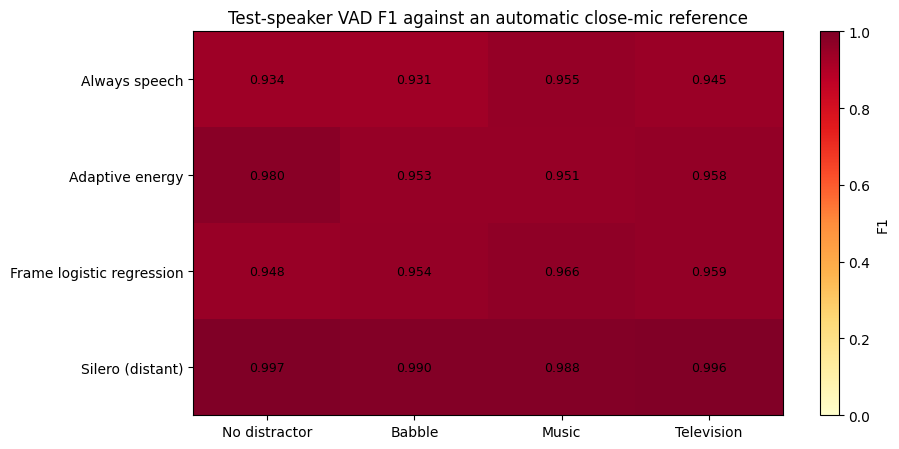

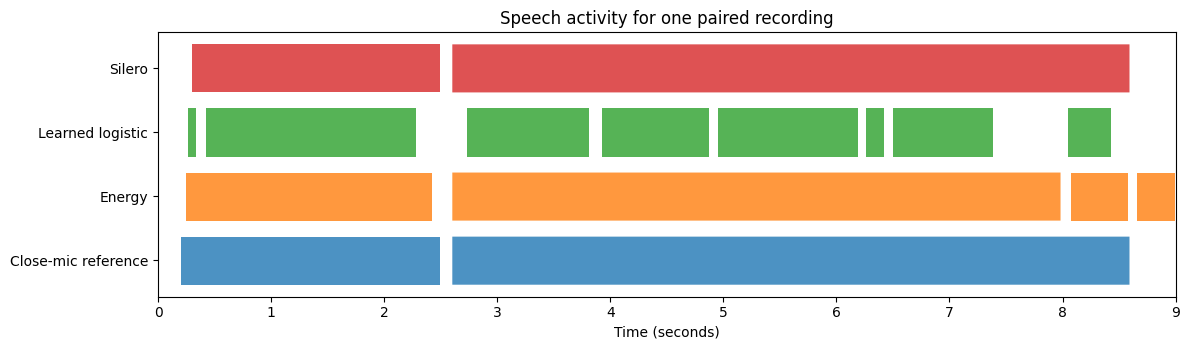

In [10]:
methods=list(vad_overall.method)
noise_chart=vad_by_noise.pivot(index='method',columns='background',values='f1').reindex(index=methods,columns=BACKGROUND)
fig,ax=plt.subplots(figsize=(9.5,4.6))
im=ax.imshow(noise_chart,cmap='YlOrRd',vmin=0,vmax=1,aspect='auto')
ax.set_xticks(range(4),[DISPLAY[x] for x in BACKGROUND]);ax.set_yticks(range(len(methods)),methods)
for (i,j),v in np.ndenumerate(noise_chart.to_numpy()):
    if np.isfinite(v): ax.text(j,i,f'{v:.3f}',ha='center',va='center',fontsize=9)
ax.set_title('Test-speaker VAD F1 against an automatic close-mic reference')
fig.colorbar(im,ax=ax,label='F1');fig.tight_layout()
fig.savefig(FIG/'06_vad_distractor_heatmap.png',dpi=170);plt.show()

case=testing[0]
t=case['times'];ref=case['reference'];energy=energy_decision(case['tracks'],energy_parameter)
learned=median_filter(frame_model.predict(case['tracks']).astype(np.uint8),size=11).astype(bool)
fig,ax=plt.subplots(figsize=(12,3.6))
for j,(name,row) in enumerate([('Reference (close)',ref),('Energy (distant)',energy),
                                ('Logistic (distant)',learned),('Silero (distant)',case['silero'])]):
    ax.fill_between(t,j+.10,j+.85,where=row,step='mid',alpha=.8,label=name)
ax.set_yticks(np.arange(4)+.48,['Close-mic reference','Energy','Learned logistic','Silero'])
ax.set_xlim(0,min(9,t[-1]));ax.set_xlabel('Time (seconds)');ax.set_title('Speech activity for one paired recording')
fig.tight_layout();fig.savefig(FIG/'07_vad_timeline.png',dpi=170);plt.show()

## 9. Discussion of my results

I compared two ways of representing the same recording. The features calculated from the quietest 30% of frames performed better in every classifier than the full-recording features. I selected the MLP (48, 24) from training-only cross-validation, where it obtained a macro-F1 of 0.843. On the separate test speakers, it reached 0.8118 accuracy and 0.7993 macro-F1. Television was the most difficult background: the model correctly classified 30 of its 54 test recordings. I think that TV is challenging because its mixture of speech, music and pauses overlaps with other conditions.

For VAD, I completed all 108 matching close/behind microphone pairs, keeping 80 pairs for training and 28 for testing. I compared the methods on 44,268 test frames. Silero on the behind microphone agreed most strongly with the close-microphone Silero reference (F1 = 0.9937), followed by the adaptive-energy method (0.9629) and the frame-level logistic regression (0.9551). The logistic classifier produced fewer false alarms (0.0424) than the energy detector (0.2271), but it missed more reference speech (0.0809 versus 0.0439).

I do not treat the VAD reference as manually verified truth. Silero created the labels on the close microphone and was also one of the methods tested on the distant microphone, which can favour it. The high proportion of reference speech frames (0.8843) also means that accuracy alone is insufficient; that is why I compare F1, false-alarm and miss rates. The low-energy frames used in background classification are an approximation to quiet intervals, not confirmed speech-free regions. These limits should be considered before applying the results to a different recording setup.

## 10. Exporting the measured results

I save the tables, figures, and an experiment summary from this execution. The printed tables report performance on speaker-separated data. Some values are rounded for display, while the CSV files produced by the code contain the original numerical precision.

In [11]:
report_lines = [
    'Mini Task 09 - VOiCES | Baraa Atmeesh | 403131113',
    f'Usable recordings: {len(df)}; unique speakers: {df.speaker.nunique()}',
    f'Background training recordings: {len(train)}; testing recordings: {len(test)}',
    f'Speaker overlap: {len(set(train.speaker)&set(test.speaker))}',
    f'Chosen background model (training CV): {best.model}',
    f'Chosen features: {best.feature_set}',
    f'Train-only CV macro F1: {best.cv_macro_f1:.4f}',
    f'Holdout accuracy: {accuracy_score(test.label,yhat):.4f}',
    f'Holdout macro F1: {f1_score(test.label,yhat,average="macro"):.4f}',
    f'VAD matched pairs: {len(pairs)}; train pairs: {len(training)}; test pairs: {len(testing)}',
    f'VAD energy threshold (training only): {energy_parameter:.3f}',
    '', 'VAD metrics against automatic reference:',
    vad_overall.to_string(index=False,float_format=lambda x:f'{x:.4f}')
]
(OUT/'measured_summary.txt').write_text('\n'.join(report_lines),encoding='utf-8')
print((OUT/'measured_summary.txt').read_text())
print('Saved figures:',len(list(FIG.glob('*.png'))))
print('Saved result tables:',len(list(OUT.glob('*.csv'))))

Mini Task 09 - VOiCES | Baraa Atmeesh | 403131113
Usable recordings: 908; unique speakers: 104
Background training recordings: 653; testing recordings: 255
Speaker overlap: 0
Chosen background model (training CV): MLP (48,24)
Chosen features: Low-energy 30%
Train-only CV macro F1: 0.8430
Holdout accuracy: 0.8118
Holdout macro F1: 0.7993
VAD matched pairs: 108; train pairs: 80; test pairs: 28
VAD energy threshold (training only): 0.050

VAD metrics against automatic reference:
                   method     frames  accuracy  precision  recall     f1  false_alarm   miss
            Always speech 44268.0000    0.8843     0.8843  1.0000 0.9386       1.0000 0.0000
          Adaptive energy 44268.0000    0.9349     0.9699  0.9561 0.9629       0.2271 0.0439
Frame logistic regression 44268.0000    0.9236     0.9940  0.9191 0.9551       0.0424 0.0809
         Silero (distant) 44268.0000    0.9889     0.9934  0.9941 0.9937       0.0508 0.0059
Saved figures: 7
Saved result tables: 8


## 11. Packaging the results

I archive the saved tables and figures without including the much larger audio files. I download this ZIP from the Colab file browser along with the executed notebook.

In [12]:
from zipfile import ZipFile, ZIP_DEFLATED
archive_out = BASE / 'Baraa_MT9_Results.zip'
with ZipFile(archive_out,'w',compression=ZIP_DEFLATED) as bundle:
    for folder in (OUT,FIG):
        for file in sorted(folder.glob('*')):
            if file.is_file():
                bundle.write(file,arcname=f'{folder.name}/{file.name}')
print('Created:',archive_out)

Created: /content/Baraa_MT9/Baraa_MT9_Results.zip


## References

1. C. Richey et al., *Voices Obscured in Complex Environmental Settings (VOICES) corpus*, Interspeech 2018. https://arxiv.org/abs/1804.05053
2. Lab41, *VOiCES-subset*. https://github.com/Lab41/VOiCES-subset
3. Silero Team, *Silero VAD*. https://github.com/snakers4/silero-vad
4. scikit-learn, *Model selection and metrics*. https://scikit-learn.org/stable/

The figures and numerical tables can be traced to the corresponding code cells in this notebook.